
# 🎬 Hollywood Movie Profitability Analysis

### Exploring profitability, audience ratings and worldwide gross

**Project type:** Exploratory Data Analysis (EDA)  
**Tools:** Python, Pandas, NumPy, Matplotlib and Seaborn  
**Dataset:** 74 movies released between 2007 and 2011

---

## 🎯 Project objective

This project explores patterns in movie profitability and worldwide gross,
compares performance across genres, and examines relationships between
audience ratings and Rotten Tomatoes scores.

## 🔍 Key business questions

1. Which genres have the highest average profitability?
2. Which movies have the highest profitability values?
3. How do audience ratings relate to profitability and worldwide gross?
4. How does the number of movies vary by release year?
5. Which studios appear most frequently in this dataset?

## 📌 Scope

This is a descriptive analysis of the available dataset.
Findings represent the movies included here and should not be
generalised to the entire film industry.


IMPORT THE LIBRARIES AND SET THE VISUAL THEME

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from google.colab import files
from IPython.display import display, Markdown

# Consistent notebook and chart styling
sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.0
)

# Professional colour palette
NAVY = "#17324D"
TEAL = "#0D9488"
ORANGE = "#F4A261"
PURPLE = "#6D5BD0"
PINK = "#D95D76"
GREEN = "#8AB17D"

PALETTE = [NAVY, TEAL, ORANGE, PURPLE, PINK, GREEN]

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["font.family"] = "DejaVu Sans"

# Create a folder for exported charts
Path("visuals").mkdir(exist_ok=True)

print("Libraries imported successfully.")
print("Visual theme configured.")



Libraries imported successfully.
Visual theme configured.


##2.UPLOADING THE DATASET

Data Loading

The original CSV file is loaded into a Pandas DataFrame.
The original dataset is retained separately so that cleaning decisions
can be documented and checked.


In [2]:

# Upload the original CSV file from your laptop
uploaded = files.upload()

# Identify the uploaded CSV
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if len(csv_files) != 1:
    raise ValueError(
        "Please upload exactly one CSV file and run this cell again."
    )

file_path = csv_files[0]

# Load the dataset
df_original = pd.read_csv(file_path)

# Keep a working copy for analysis
df = df_original.copy()

print("File loaded:", file_path)
print("Dataset loaded successfully!")


Saving hollywood_movies.csv.csv to hollywood_movies.csv.csv
File loaded: hollywood_movies.csv.csv
Dataset loaded successfully!


##3. UNDERSTAND THE DATA


Initial Data Exploration

Before cleaning the data, we inspect its dimensions, column names,
data types, sample records and missing values.


In [3]:
# View the first five rows
print("FIRST FIVE ROWS")
display(df.head())

# Dataset dimensions
print("\nDATASET SHAPE")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

# Column names and data types
print("\nDATA TYPES AND NON-NULL COUNTS")
df.info()

# Descriptive statistics
print("\nNUMERICAL SUMMARY")
display(df.describe().round(2))

# Missing values
print("\nMISSING VALUES BY COLUMN")
display(df.isnull().sum().to_frame("missing_count"))


FIRST FIVE ROWS


,Film,Genre,Lead Studio,Audience score %,Profitability,Rotten Tomatoes %,Worldwide Gross,Year
0,27 Dresses,Comedy,Fox,71.0,5.343622,40.0,160.308654,2008
1,(500) Days of Summer,Comedy,Fox,81.0,8.096000,87.0,60.720000,2009
2,A Dangerous Method,Drama,Independent,89.0,0.448645,79.0,8.972895,2011
3,A Serious Man,Drama,Universal,64.0,4.382857,89.0,30.680000,2009
4,Across the Universe,Romance,Independent,84.0,0.652603,54.0,29.367143,2007



DATASET SHAPE
Rows: 74
Columns: 8

DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Film               74 non-null     object 
 1   Genre              74 non-null     object 
 2   Lead Studio        73 non-null     object 
 3   Audience  score %  73 non-null     float64
 4   Profitability      71 non-null     float64
 5   Rotten Tomatoes %  73 non-null     float64
 6   Worldwide Gross    74 non-null     float64
 7   Year               74 non-null     int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 4.8+ KB

NUMERICAL SUMMARY


,Audience score %,Profitability,Rotten Tomatoes %,Worldwide Gross,Year
count,73.00,71.00,73.00,74.00,74.00
mean,64.14,4.74,47.36,136.35,2009.05
std,13.65,8.29,26.24,157.07,1.35
min,35.00,0.00,3.00,0.02,2007.00
25%,52.00,1.79,27.00,32.45,2008.00
50%,64.00,2.64,45.00,73.20,2009.00
75%,76.00,4.85,65.00,190.19,2010.00
max,89.00,66.93,96.00,709.82,2011.00



MISSING VALUES BY COLUMN


,missing_count
Film,0
Genre,0
Lead Studio,1
Audience score %,1
Profitability,3
Rotten Tomatoes %,1
Worldwide Gross,0
Year,0


## 4. DATA CLEANING AND PREPARATION


Data Cleaning and Preparation

Column names are standardised to make them consistent and easier to use
in Python and SQL.


In [4]:

# Standardise column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace("%", "percent", regex=False)
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Standardised column names:")
print(df.columns.tolist())


Standardised column names:
['film', 'genre', 'lead_studio', 'audience_score_percent', 'profitability', 'rotten_tomatoes_percent', 'worldwide_gross', 'year']


## 5. CHECKING THE DATA QUALITY

In [5]:

# Check missing values and duplicate records
print("MISSING VALUES")
display(df.isnull().sum().to_frame("missing_count"))

print("\nEXACT DUPLICATE ROWS")
print(df.duplicated().sum())

print("\nDATA TYPES")
display(df.dtypes.to_frame("data_type"))

print("\nYEAR RANGE")
print(df["year"].min(), "to", df["year"].max())


MISSING VALUES


,missing_count
film,0
genre,0
lead_studio,1
audience_score_percent,1
profitability,3
rotten_tomatoes_percent,1
worldwide_gross,0
year,0



EXACT DUPLICATE ROWS
0

DATA TYPES


,data_type
film,object
genre,object
lead_studio,object
audience_score_percent,float64
profitability,float64
rotten_tomatoes_percent,float64
worldwide_gross,float64
year,int64



YEAR RANGE
2007 to 2011


## 6. DATASET CLEANING

We'll keep df_original unchanged and apply cleaning decisions to a new DataFrame called df_clean.

In [6]:

# Create a separate cleaned copy
df_clean = df.copy()

# Standardise text fields
for col in ["film", "genre", "lead_studio"]:
    df_clean[col] = df_clean[col].apply(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# Replace missing studio name with an explicit category
df_clean["lead_studio"] = df_clean["lead_studio"].fillna("Unknown")

# Remove exact duplicate rows if any exist
df_clean = df_clean.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
display(df_clean.isnull().sum().to_frame("missing_count"))

print("\nDuplicate rows remaining:", df_clean.duplicated().sum())


Original dataset shape: (74, 8)
Cleaned dataset shape: (74, 8)

Missing values after cleaning:


,missing_count
film,0
genre,0
lead_studio,0
audience_score_percent,1
profitability,3
rotten_tomatoes_percent,1
worldwide_gross,0
year,0



Duplicate rows remaining: 0


SUMMARY OF THE DATASET

In [7]:

print(f"Total movies: {len(df_clean)}")
print(f"Total columns: {len(df_clean.columns)}")
print(f"Release period: {df_clean['year'].min()}–{df_clean['year'].max()}")

print("\nMovies by genre:")
display(df_clean["genre"].value_counts().to_frame("movie_count"))

print("\nMovies by year:")
display(
    df_clean["year"]
    .value_counts()
    .sort_index()
    .to_frame("movie_count")
)


Total movies: 74
Total columns: 8
Release period: 2007–2011

Movies by genre:


,movie_count
genre,
Comedy,41
Romance,15
Drama,13
Animation,3
Action,1
Fantasy,1



Movies by year:


,movie_count
year,
2007,11
2008,19
2009,12
2010,19
2011,13


## 7. DATA QUALITY DASHBOARD


Data Quality Assessment

This section evaluates missing values, duplicate records and dataset completeness
before interpreting the results.

Understanding data quality helps identify limitations that may affect
the reliability of the analysis.


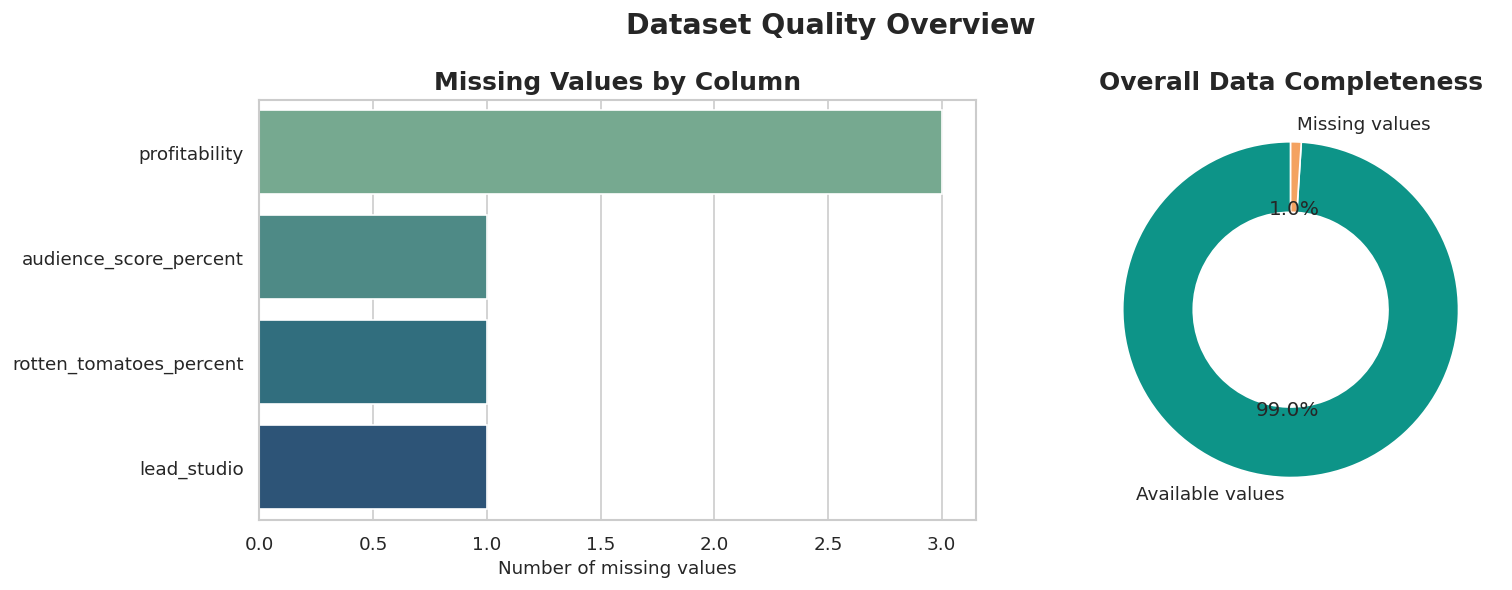

Total rows: 74
Exact duplicate rows: 0
Total missing cells: 6
Total cells: 592


In [8]:

# ============================================================
# STEP 10: DATA QUALITY VISUALISATION
# ============================================================

missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Missing values
if not missing.empty:
    sns.barplot(
        x=missing.values,
        y=missing.index,
        hue=missing.index,
        palette="crest",
        legend=False,
        ax=axes[0]
    )
    axes[0].set_title("Missing Values by Column")
    axes[0].set_xlabel("Number of missing values")
    axes[0].set_ylabel("")
else:
    axes[0].text(0.5, 0.5, "No missing values", ha="center", va="center")
    axes[0].set_axis_off()

# Chart 2: Valid vs missing cells
total_cells = df.size
missing_cells = int(df.isnull().sum().sum())
valid_cells = total_cells - missing_cells

axes[1].pie(
    [valid_cells, missing_cells],
    labels=["Available values", "Missing values"],
    autopct="%1.1f%%",
    colors=[TEAL, ORANGE],
    startangle=90,
    wedgeprops={"width": 0.42, "edgecolor": "white"}
)
axes[1].set_title("Overall Data Completeness")

fig.suptitle("Dataset Quality Overview", fontsize=17, fontweight="bold")
plt.tight_layout()
plt.savefig("visuals/01_data_quality.png", bbox_inches="tight")
plt.show()

print("Total rows:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())
print("Total missing cells:", missing_cells)
print("Total cells:", total_cells)


## 8. VISUALIZING AND COMPARING THE PROFITABILITY ACROSS THE GENRES



Profitability Across Movie Genres

This section compares profitability values across genres using a box plot and summary statistics.

The box plot helps identify differences in the distribution of profitability, including the median, spread and potential outliers. Average profitability is also calculated for each genre.

Genres with very few movies should be interpreted cautiously.



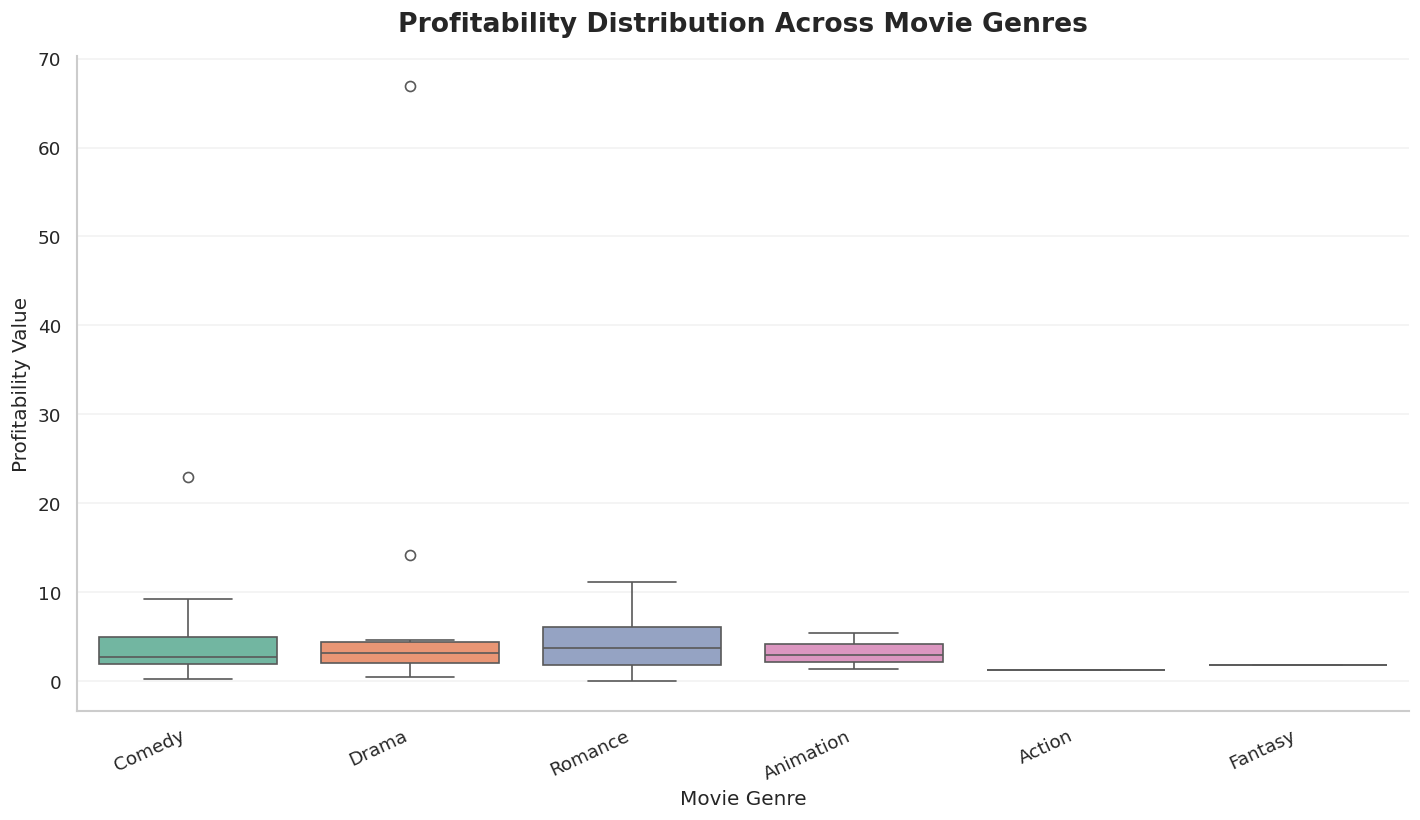

PROFITABILITY SUMMARY BY GENRE


,movie_count,average_profitability,median_profitability,minimum_profitability,maximum_profitability
genre,,,,,
Drama,13,8.41,3.08,0.45,66.93
Romance,14,4.37,3.67,0.00,11.09
Comedy,39,3.94,2.64,0.25,22.91
Animation,3,3.22,2.90,1.37,5.39
Fantasy,1,1.78,1.78,1.78,1.78
Action,1,1.25,1.25,1.25,1.25


In [9]:

# STEP 13: Compare profitability across genres

# 1. Select rows with both genre and profitability available
profit_data = df_clean.dropna(
    subset=["genre", "profitability"]
).copy()

# 2. Calculate summary statistics for each genre
genre_profitability_summary = (
    profit_data.groupby("genre")
    .agg(
        movie_count=("film", "count"),
        average_profitability=("profitability", "mean"),
        median_profitability=("profitability", "median"),
        minimum_profitability=("profitability", "min"),
        maximum_profitability=("profitability", "max")
    )
    .sort_values("average_profitability", ascending=False)
    .round(2)
)

# 3. Create the box plot
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=profit_data,
    x="genre",
    y="profitability",
    hue="genre",
    palette="Set2",
    legend=False
)

plt.title(
    "Profitability Distribution Across Movie Genres",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Movie Genre", fontsize=12)
plt.ylabel("Profitability Value", fontsize=12)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
sns.despine()

plt.tight_layout()

# 4. Save the chart
plt.savefig(
    "visuals/04_profitability_by_genre.png",
    dpi=300,
    bbox_inches="tight"
)

# 5. Display the chart
plt.show()

# 6. Display the summary table
print("PROFITABILITY SUMMARY BY GENRE")
display(genre_profitability_summary)


## 9. FINDING THE TOP 10 MOST PROFITABLE MOVIES

This section identifies the ten movies with the highest recorded profitability values.

A horizontal bar chart makes it easier to compare the movies and identify the highest value. The table also shows each movie's genre, lead studio, worldwide gross and release year.

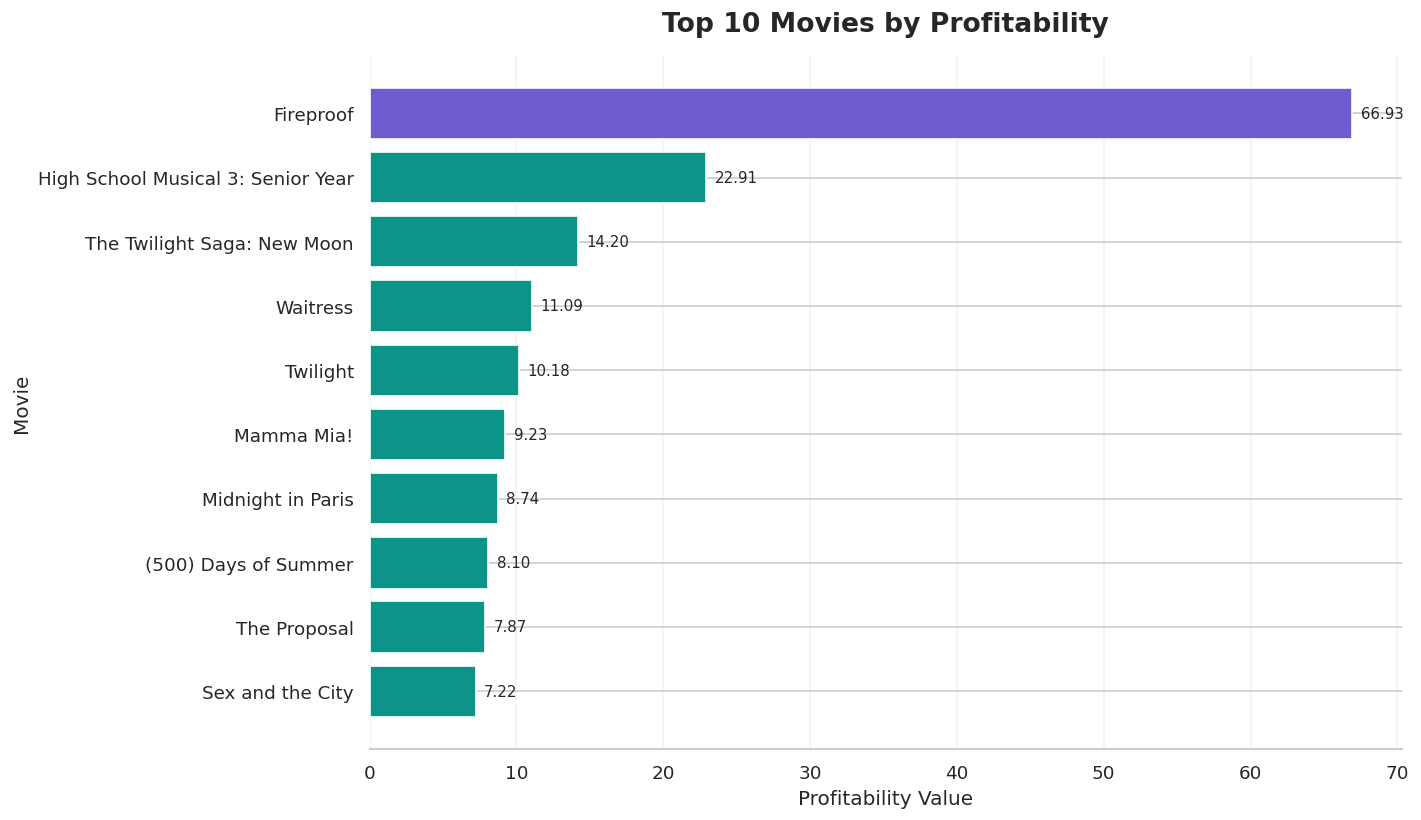

TOP 10 MOVIES BY PROFITABILITY


,film,genre,lead_studio,profitability,worldwide_gross,year
0,Fireproof,Drama,Independent,66.934000,33.467000,2008
1,High School Musical 3: Senior Year,Comedy,Disney,22.913136,252.044501,2008
2,The Twilight Saga: New Moon,Drama,Summit,14.196400,709.820000,2009
3,Waitress,Romance,Independent,11.089742,22.179483,2007
4,Twilight,Romance,Summit,10.180027,376.661000,2008
5,Mamma Mia!,Comedy,Universal,9.234454,609.473955,2008
6,Midnight in Paris,Romance,Sony,8.744706,148.660000,2011
7,(500) Days of Summer,Comedy,Fox,8.096000,60.720000,2009
8,The Proposal,Comedy,Disney,7.867500,314.700000,2009
9,Sex and the City,Comedy,Warner Bros.,7.221796,415.253258,2008


In [10]:
# STEP 14: Find the top 10 movies by profitability

# 1. Remove rows where profitability is missing
profitability_data = df_clean.dropna(
    subset=["profitability", "film"]
).copy()

# 2. Select the 10 movies with the highest profitability values
top10 = profitability_data.nlargest(
    10, "profitability"
).sort_values(
    "profitability", ascending=True
)

# 3. Create the horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 7))

bar_colors = [
    PURPLE if value == top10["profitability"].max() else TEAL
    for value in top10["profitability"]
]

bars = ax.barh(
    top10["film"],
    top10["profitability"],
    color=bar_colors
)

# Display the value beside each bar
ax.bar_label(
    bars,
    fmt="%.2f",
    padding=5,
    fontsize=9
)

# Add chart titles and labels
ax.set_title(
    "Top 10 Movies by Profitability",
    fontsize=16,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Profitability Value", fontsize=12)
ax.set_ylabel("Movie", fontsize=12)

# Improve chart appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

# Save the chart
plt.savefig(
    "visuals/05_top_10_movies.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()

# Display the top 10 movies in descending order
print("TOP 10 MOVIES BY PROFITABILITY")

display(
    top10.sort_values(
        "profitability", ascending=False
    )[
        [
            "film",
            "genre",
            "lead_studio",
            "profitability",
            "worldwide_gross",
            "year"
        ]
    ].reset_index(drop=True)
)

## 10. EXPLORING AUDIENCE SCORES AND PROFITABILITY

Audience Scores vs Profitability

This section investigates whether movies with higher audience scores also tend to have higher profitability values.

A scatter plot displays each movie as a point. The pattern of points can help reveal whether the two variables have a positive, negative or weak relationship.

This analysis explores association only; it does not establish cause and effect.

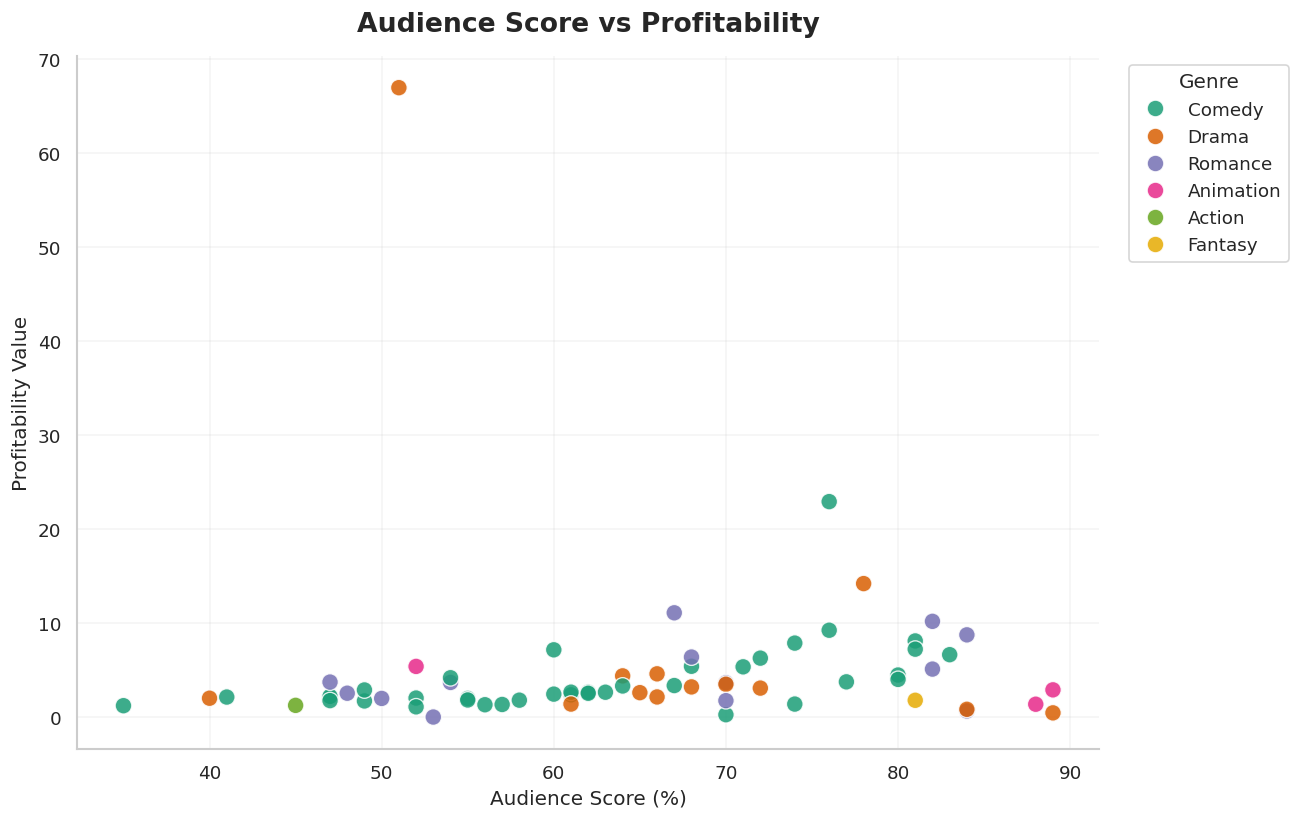

Correlation between audience score and profitability: 0.042


In [11]:
# STEP 15: Audience scores vs profitability

# 1. Select rows with the required values
scatter_data = df_clean.dropna(
    subset=[
        "audience_score_percent",
        "profitability",
        "genre"
    ]
).copy()

# 2. Create the scatter plot
fig, ax = plt.subplots(figsize=(11, 7))

sns.scatterplot(
    data=scatter_data,
    x="audience_score_percent",
    y="profitability",
    hue="genre",
    palette="Dark2",
    s=100,
    alpha=0.85,
    ax=ax
)

# 3. Add chart titles and labels
ax.set_title(
    "Audience Score vs Profitability",
    fontsize=16,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Audience Score (%)", fontsize=12)
ax.set_ylabel("Profitability Value", fontsize=12)

# 4. Improve chart appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)

ax.legend(
    title="Genre",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

# 5. Save and display the chart
plt.savefig(
    "visuals/06_audience_vs_profitability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Calculate the correlation
audience_profitability_correlation = scatter_data[
    ["audience_score_percent", "profitability"]
].corr().iloc[0, 1]

print(
    "Correlation between audience score and profitability:",
    round(audience_profitability_correlation, 3)
)

## 11. CREATING A CORRELATION HEATMAP

Correlation Between Movie Metrics

This section examines the relationships between audience scores, Rotten Tomatoes scores, profitability and worldwide gross.

A correlation heatmap summarises the strength and direction of linear relationships between numerical variables. Correlation values range from -1 to +1.

- Values closer to +1 indicate a positive linear relationship.
- Values closer to -1 indicate a negative linear relationship.
- Values closer to 0 indicate a weak linear relationship.

Correlation does not imply causation.

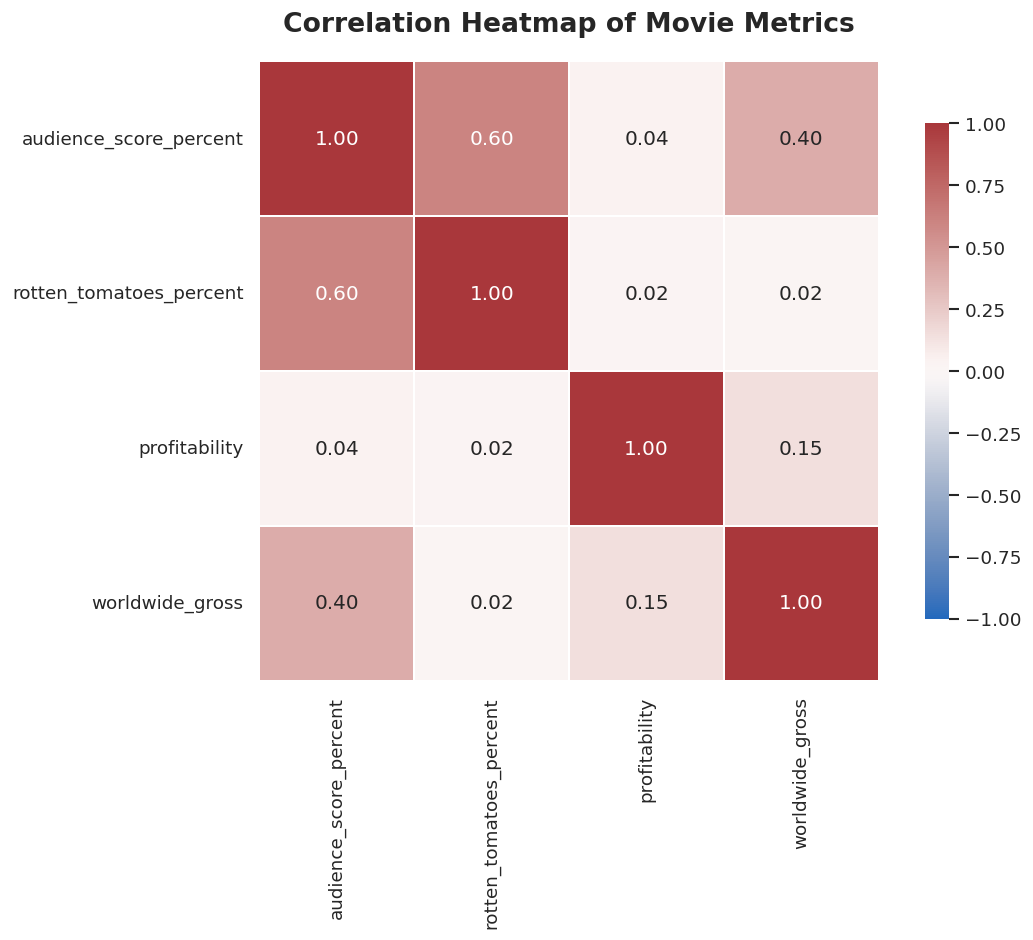

CORRELATION MATRIX


,audience_score_percent,rotten_tomatoes_percent,profitability,worldwide_gross
audience_score_percent,1.00,0.60,0.04,0.40
rotten_tomatoes_percent,0.60,1.00,0.02,0.02
profitability,0.04,0.02,1.00,0.15
worldwide_gross,0.40,0.02,0.15,1.00


In [12]:
# STEP 16: Create a correlation heatmap

# 1. Select the numerical columns for analysis
numeric_columns = [
    "audience_score_percent",
    "rotten_tomatoes_percent",
    "profitability",
    "worldwide_gross"
]

# 2. Calculate the correlation matrix
correlation_matrix = df_clean[numeric_columns].corr()

# 3. Create the heatmap
fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=1,
    cbar_kws={"shrink": 0.8},
    ax=ax
)

# 4. Add a title
ax.set_title(
    "Correlation Heatmap of Movie Metrics",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.tight_layout()

# 5. Save and display the chart
plt.savefig(
    "visuals/07_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Display the correlation matrix as a table
print("CORRELATION MATRIX")
display(correlation_matrix.round(2))

## 12. ANALYZING THE MOST FREQUENTLY REPRESENTED STUDIOS

Studio Representation

This section identifies the ten lead studios that appear most frequently in the dataset.

The chart measures the number of movies associated with each studio. It does not measure studio market share, total revenue or profitability.

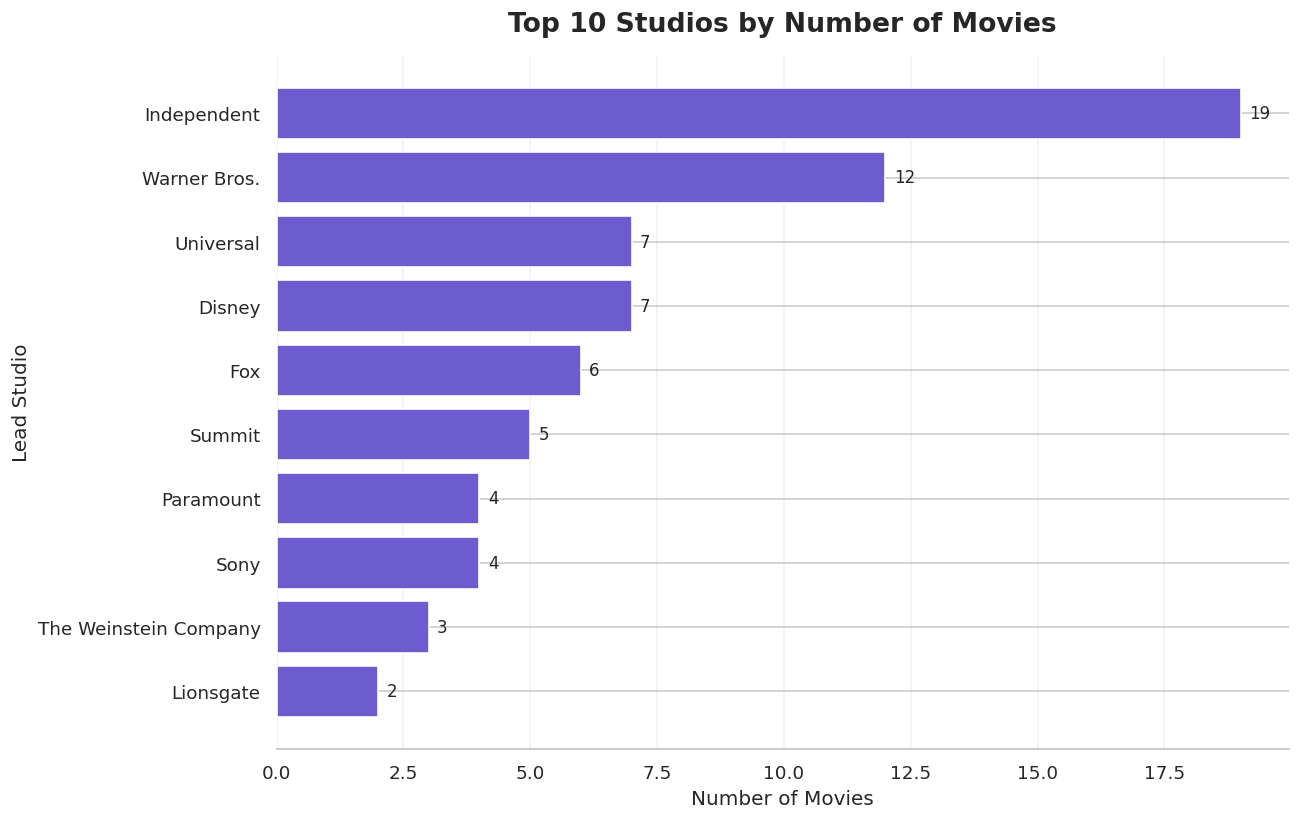

TOP 10 STUDIOS BY MOVIE COUNT


,movie_count
lead_studio,
Independent,19
Warner Bros.,12
Disney,7
Universal,7
Fox,6
Summit,5
Sony,4
Paramount,4
The Weinstein Company,3


In [13]:
# STEP 17: Analyse the top 10 studios by movie count

# 1. Count movies by lead studio
studio_counts = (
    df_clean["lead_studio"]
    .fillna("Unknown")
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

# 2. Create the horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    studio_counts.index,
    studio_counts.values,
    color=PURPLE
)

# Display the movie count beside each bar
ax.bar_label(
    bars,
    padding=5,
    fontsize=10
)

# 3. Add titles and labels
ax.set_title(
    "Top 10 Studios by Number of Movies",
    fontsize=16,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Number of Movies", fontsize=12)
ax.set_ylabel("Lead Studio", fontsize=12)

# 4. Improve chart appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

# 5. Save and display the chart
plt.savefig(
    "visuals/08_top_studios.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Display the studio counts
print("TOP 10 STUDIOS BY MOVIE COUNT")

display(
    studio_counts.sort_values(
        ascending=False
    ).to_frame("movie_count")
)

## 13. FINAL FINDINGS, LIMITATIONS AND CONCLUSION

## Key Findings

### 1. Genre Representation
Comedy is the most frequently represented genre in this dataset. Other genres have fewer observations, so comparisons involving them should be interpreted cautiously.

### 2. Profitability Across Genres
The genre summary helps compare average and median profitability. Differences between these measures may indicate that unusually high or low observations influence the average.

### 3. Top Movies by Profitability
The top 10 ranking identifies the movies with the highest recorded profitability values in the dataset. These values should be interpreted according to the original source's definition of profitability.

### 4. Audience Scores and Profitability
The scatter plot and correlation calculation help investigate whether audience scores are linearly associated with profitability in this sample.

### 5. Movie Ratings
The correlation heatmap compares audience scores, Rotten Tomatoes scores, profitability and worldwide gross. Correlations describe associations, not cause-and-effect relationships.

### 6. Studio Representation
The studio analysis shows which lead studios appear most frequently in the dataset. Frequency alone does not establish financial performance or market share.

### 7. Data Quality
The dataset was checked for missing values and duplicate records. Missing numerical values were not automatically replaced with zero or an assumed average.

## Limitations

- The dataset contains only 74 movies from 2007 to 2011.
- Some genres have very few movies.
- Missing numerical values may affect individual analyses.
- The definitions and units of profitability and worldwide gross should be verified against the original dataset documentation.
- Correlation does not imply causation.
- The findings describe this dataset and should not be generalised to the entire Hollywood film industry.

## Conclusion

This project demonstrates an exploratory data analysis workflow using Python, Pandas, NumPy, Matplotlib and Seaborn.

The analysis covers data loading, quality checks, cleaning, genre comparisons, profitability rankings, rating relationships, correlation analysis and studio representation.

The resulting charts and summary tables provide a foundation for further analysis using SQL and an interactive Power BI dashboard.

## 14. FINAL SUMMARY TABLES

This section brings the main genre statistics, highest-profitability movies and data-quality information together for easy reference.

In [14]:
# STEP 19: Create final summary tables

# TABLE 1: Genre-level summary
genre_summary = (
    df_clean.groupby("genre")
    .agg(
        movie_count=("film", "count"),
        average_profitability=("profitability", "mean"),
        median_profitability=("profitability", "median"),
        average_worldwide_gross=("worldwide_gross", "mean")
    )
    .round(2)
    .sort_values(
        "average_profitability",
        ascending=False,
        na_position="last"
    )
)

print("=" * 60)
print("TABLE 1: SUMMARY BY GENRE")
print("=" * 60)
display(genre_summary)


# TABLE 2: Top 5 movies by profitability
top5_movies = (
    df_clean.dropna(subset=["profitability"])
    .nlargest(5, "profitability")
    [
        [
            "film",
            "genre",
            "profitability",
            "worldwide_gross",
            "year"
        ]
    ]
    .reset_index(drop=True)
)

print("=" * 60)
print("TABLE 2: TOP 5 MOVIES BY PROFITABILITY")
print("=" * 60)
display(top5_movies)


# TABLE 3: Data-quality summary
quality_summary = pd.DataFrame({
    "metric": [
        "Total movies after cleaning",
        "Total columns",
        "Exact duplicate rows after cleaning",
        "Missing cells before cleaning",
        "Missing numerical values retained"
    ],
    "value": [
        len(df_clean),
        len(df_clean.columns),
        int(df_clean.duplicated().sum()),
        int(df.isnull().sum().sum()),
        int(
            df_clean[
                df_clean.select_dtypes(include="number").columns
            ].isnull().sum().sum()
        )
    ]
})

print("=" * 60)
print("TABLE 3: DATA QUALITY SUMMARY")
print("=" * 60)
display(quality_summary)

TABLE 1: SUMMARY BY GENRE


,movie_count,average_profitability,median_profitability,average_worldwide_gross
genre,,,,
Drama,13,8.41,3.08,99.01
Romance,15,4.37,3.67,133.54
Comedy,41,3.94,2.64,130.50
Animation,3,3.22,2.90,356.78
Fantasy,1,1.78,1.78,285.43
Action,1,1.25,1.25,93.40


TABLE 2: TOP 5 MOVIES BY PROFITABILITY


,film,genre,profitability,worldwide_gross,year
0,Fireproof,Drama,66.934000,33.467000,2008
1,High School Musical 3: Senior Year,Comedy,22.913136,252.044501,2008
2,The Twilight Saga: New Moon,Drama,14.196400,709.820000,2009
3,Waitress,Romance,11.089742,22.179483,2007
4,Twilight,Romance,10.180027,376.661000,2008


TABLE 3: DATA QUALITY SUMMARY


,metric,value
0,Total movies after cleaning,74
1,Total columns,8
2,Exact duplicate rows after cleaning,0
3,Missing cells before cleaning,6
4,Missing numerical values retained,5


## SAVING TABLES AS CSV FILES

In [15]:
# STEP 19B: Export summary tables as CSV files

genre_summary.to_csv(
    "genre_profitability_summary.csv",
    index=True
)

top5_movies.to_csv(
    "top_5_movies_by_profitability.csv",
    index=False
)

quality_summary.to_csv(
    "data_quality_summary.csv",
    index=False
)

print("All three summary tables have been saved as CSV files.")

All three summary tables have been saved as CSV files.


## EXPORTING ALL THE CHARTS INTO ONE ZIP FILE

In [16]:
# STEP 20: Export all saved charts into a ZIP file

import shutil
from pathlib import Path

# Find all PNG chart files
visual_folder = Path("visuals")
visual_files = sorted(visual_folder.glob("*.png"))

# Display the chart files found
print("CHARTS FOUND")
for file in visual_files:
    print("-", file.name)

print("\nTotal charts found:", len(visual_files))

# Create a ZIP file if charts are available
if len(visual_files) > 0:

    zip_path = shutil.make_archive(
        "hollywood_movie_visuals",
        "zip",
        root_dir=str(visual_folder)
    )

    print("\nChart ZIP file created successfully:")
    print(zip_path)

else:
    print(
        "\nNo chart images were found. "
        "Run Steps 10–17 again and check that each chart is saved."
    )

CHARTS FOUND
- 01_data_quality.png
- 04_profitability_by_genre.png
- 05_top_10_movies.png
- 06_audience_vs_profitability.png
- 07_correlation_heatmap.png
- 08_top_studios.png

Total charts found: 6

Chart ZIP file created successfully:
/content/hollywood_movie_visuals.zip


In [17]:
# STEP 20B: Download the chart ZIP file to your computer

from google.colab import files

files.download("hollywood_movie_visuals.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>